#Пешков Егор Экзамен

In [56]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LogisticRegression
from rink import plot_rink

pd.set_option('display.precision', 3)
pd.set_option('display.width', 120)
sns.set_theme(style='whitegrid')

##№1

Читаем эксель файл, при этом используя первый столбец как индекс.

In [57]:
events = pd.read_excel('NHL-playoffs-2026.xlsx', index_col=0)
print(events.shape)
events.iloc[:10, [2, 3, 4, 9, 12]]

(29710, 38)


,Date,Away Team,Home Team,Remaining Time,Play Type
0,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,period-start
1,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,faceoff
2,2026-04-19,Boston Bruins,Buffalo Sabres,19:47,hit
3,2026-04-19,Boston Bruins,Buffalo Sabres,19:46,hit
4,2026-04-19,Boston Bruins,Buffalo Sabres,19:41,hit
5,2026-04-19,Boston Bruins,Buffalo Sabres,19:27,hit
6,2026-04-19,Boston Bruins,Buffalo Sabres,19:03,hit
7,2026-04-19,Boston Bruins,Buffalo Sabres,18:53,missed-shot
8,2026-04-19,Boston Bruins,Buffalo Sabres,18:48,hit
9,2026-04-19,Boston Bruins,Buffalo Sabres,18:37,missed-shot


##№2

Счёт берём из последней записи каждой игры (поля Cumulated Away/Home Score содержат суммарный счёт на момент определённой записи), поэтому если взять последнюю запись из игры, то она будет содержать итоговый результат по забитым шайбам для хозяев и гостей. Число овертаймов определяется по максимальному номеру периода: 3 — Final, 4 — Final/OT, 5 — Final/2OT и т. д.

In [58]:
last = events.groupby('Game ID').last()
games = last[['Date', 'Away Team', 'Home Team']].copy()
games['Away Score'] = last['Cumulated Away Score']
games['Home Score'] = last['Cumulated Home Score']

def outcome(max_period):
    if max_period <= 3:
        return 'Final'
    if max_period == 4:
        return 'Final/OT'
    return f'Final/{max_period - 3}OT'

games['Outcome'] = events.groupby('Game ID')['Period'].max().map(outcome)
print(games.columns)
games.iloc[-5:, -4:]

Index(['Date', 'Away Team', 'Home Team', 'Away Score', 'Home Score', 'Outcome'], dtype='object')


,Home Team,Away Score,Home Score,Outcome
Game ID,,,,
2025030412,Carolina Hurricanes,3,4,Final/OT
2025030413,Vegas Golden Knights,4,5,Final/2OT
2025030414,Vegas Golden Knights,5,3,Final
2025030415,Carolina Hurricanes,2,4,Final
2025030416,Vegas Golden Knights,3,0,Final


##№3

Функция берёт строку таблицы games по индексу (Game ID) через .loc — это быстрый поиск без фильтрации всей таблицы событий. Как основа для функции брался пример из самого задания: сначала хозяева, затем гости, счёт в том же порядке, итог игры (к-во или отсутсвие овертаймов, а также когда состоялась игра)

In [59]:
def gameInfo(gameId):
    g = games.loc[gameId]
    return (f"{g['Home Team']} - {g['Away Team']} "
            f"({g['Home Score']} - {g['Away Score']}, {g['Outcome']}, {g['Date']})")

print(gameInfo(games.index.min()))
print(gameInfo(games.index.max()))

Buffalo Sabres - Boston Bruins (4 - 3, Final, 2026-04-19)
Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)


##№4

Сумма счёта гостей и хозяев включает голы в овертаймах, так как именно столько шайб было заброшено в матче. Описательные статистики вывел с помощью describe().

In [60]:
games['Total Score'] = games['Away Score'] + games['Home Score']
games['Total Score'].describe()

,Total Score
count,82.000
mean,5.927
std,2.260
min,1.000
25%,5.000
50%,6.000
75%,7.000
max,15.000


##№5  

Как и было предложено в задании был использован seaborn.countplot для создания гистограммы распределения голов в одном матче. Что касается результатов, то стоит отметить, что в среднем можно ожидать в районе 5, 6 и 7 голов. Количество игр с 5 забитыми шайбами самое большое в рамках плейофф сезона NHL 2025-26 (19 игр). Самым интересным моментом здесь является то, что было одна игра, где было забито 15!!! шайб.

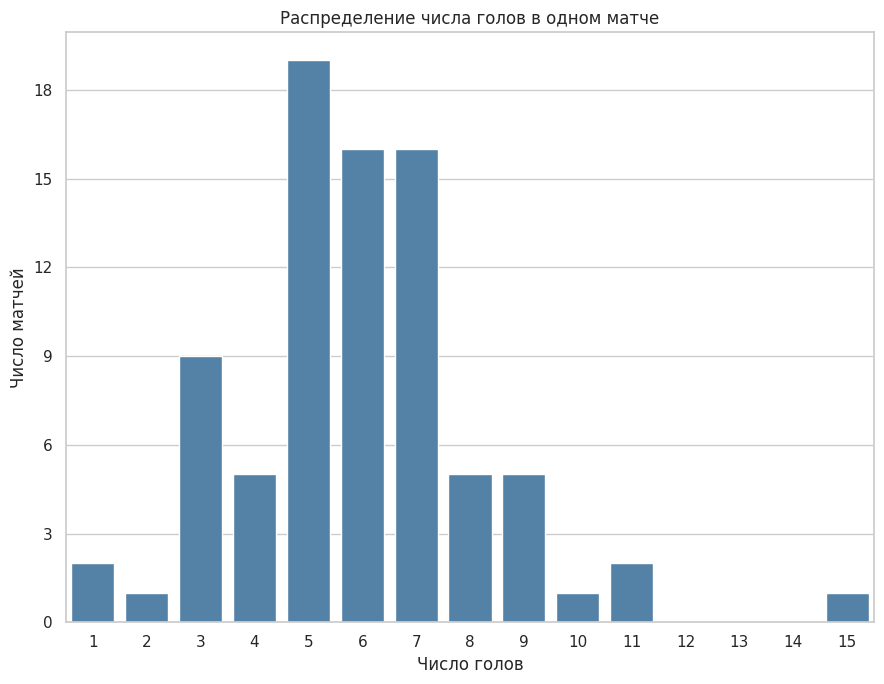

In [61]:
fig, ax = plt.subplots(figsize=(9, 7))
sns.countplot(x=games['Total Score'], order=range(1, 16), color='steelblue', ax=ax)
ax.set_xlabel('Число голов')
ax.set_ylabel('Число матчей')
ax.set_yticks(range(0, 19, 3))
ax.set_title('Распределение числа голов в одном матче')
plt.tight_layout()
plt.show()

##№6

Так как количество игр с определённым количеством забитых голов может быть больше 1, то для поиска таких игр используем равенство забитых голов определённых игр с мин/макс забитых шайб в течение одной игры в рамках плей-офф.

In [62]:
low = games.index[games['Total Score'] == games['Total Score'].min()]
high = games.index[games['Total Score'] == games['Total Score'].max()]
display([gameInfo(i) for i in low])
display([gameInfo(i) for i in high])

['Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)',
 'Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)']

['Colorado Avalanche - Minnesota Wild (9 - 6, Final, 2026-05-03)']

##№7

Для выполнения данного пункта собрал все фамилии из полей Away/Home Team's Player on the Ice #1–#6 и полей вратарей, затем перевёл эти данные с помощью melt в удобный для меня формат (в котором вместо отдельных столбцов для Away Player #1 есть общее поле для игрока, без учёта его позиции на поле), отбросил пропуски и дубликаты пар «игра — игрок» и посчитал число уникальных фамилий в каждой игре. Пропуски отбросил, так как NaN — это отсутствие игрока, а не игрок.

In [63]:
onice_cols = ([f"{side} Team's Player on the Ice #{i}" for side in ['Away', 'Home'] for i in range(1, 7)]
              + ["Away Team's Goalie", "Home Team's Goalie"])
onice = (events.melt(id_vars='Game ID', value_vars=onice_cols, value_name='Player')
               [['Game ID', 'Player']].dropna().drop_duplicates())

games['Player Count'] = onice.groupby('Game ID').size()
games['Game Info'] = [gameInfo(i) for i in games.index]
games.loc[games['Player Count'] == games['Player Count'].max(), ['Game Info', 'Player Count']]

,Game Info,Player Count
Game ID,,
2025030216,"Montréal Canadiens - Buffalo Sabres (3 - 8, Fi...",40


##№8

Ворота, в которые бьёт команда: если Home Team's Defending Side = left, хозяева бьют в правые ворота (X = 89), гости — в левые (X = -89). Затем по формуле из условия (через np.select выбираем нужный случай в зависимости от того, выше, ниже или на уровне створа находится y) высчитываем расстояние до ближайшей точки ворот, и сохраняем это только для бросков.

In [64]:
SHOT_TYPES = ['shot-on-goal', 'goal', 'missed-shot']
is_shot = events['Play Type'].isin(SHOT_TYPES)
is_home = events['Team Making the Play'] == events['Home Team']
home_defends_left = events["Home Team's Defending Side"] == 'left'

X = np.where(is_home == home_defends_left, 89, -89)
events['Target X'] = X

x = events['X Coordinate on the Ice Rink']
y = events['Y Coordinate on the Ice Rink']

conditions = [
    y < -3,
    (y >= -3) & (y <= 3),
    y > 3,
]
choices = [
    np.sqrt((x - X) ** 2 + (y + 3) ** 2),
    np.abs(x - X),
    np.sqrt((x - X) ** 2 + (y - 3) ** 2),
]
d = np.select(conditions, choices, default=np.nan)

events['Shot Length'] = np.where(is_shot, d, np.nan)

events[is_shot][['Game ID', 'Play Type', 'Shot Length']]

,Game ID,Play Type,Shot Length
7,2025030111,missed-shot,12.207
9,2025030111,missed-shot,12.000
12,2025030111,missed-shot,29.411
13,2025030111,shot-on-goal,62.169
19,2025030111,missed-shot,52.924
...,...,...,...
29695,2025030416,missed-shot,54.083
29696,2025030416,missed-shot,5.099
29704,2025030416,goal,46.239
29706,2025030416,missed-shot,60.926


##№9

Так как подвыборки разного размера, то в данном случае будем использовать плотности, нормированные внутри каждой группы: stat='density' и common_norm=False. Тогда площадь под каждой гистограммой равна 1, и видно, с каких расстояний бросают относительно чаще, а не просто «точных больше». Ширина интервала 5 футов. Голы относим к точным броскам, так как гол — это бросок в створ. Использовал seaborn.displot для создания гистограммы в соответствии с условием задания.

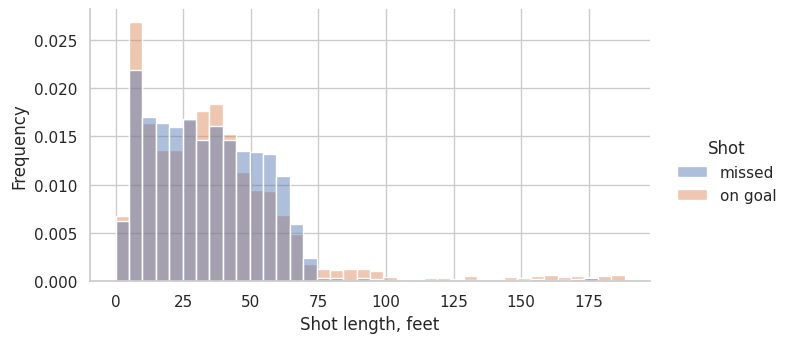

In [65]:
shots = events[is_shot].copy()
shots['Shot'] = np.where(shots['Play Type'] == 'missed-shot', 'missed', 'on goal')

g = sns.displot(data=shots, x='Shot Length', hue='Shot', hue_order=['missed', 'on goal'],
                stat='density', common_norm=False, binwidth=5, alpha=0.45,
                height=3.6, aspect=1.9)
g.set_axis_labels('Shot length, feet', 'Frequency')

Основная масса бросков наносится с 5-60 футов. Самое большое количество бросков с 5 до 10 футов, почти вплотную с воротами, там и доля бросков в створ выше. Дальше в среднем больше промахнувшихся бросков до 75 футов. Также стоит выделить броски в пределах 30-45 футов, где больше доля ударов в створ. Это можно обхяснить тем, что в этих пределах находятся точки вбрасывания, откуда проще соверщить более точный бросок.

Количество точных бросков со своей половины можно объяснить выносом шайбы защитниками со своей стороны поля в сторону чужих ворот, такие броски обычно более меделенные и спокойно останавливаются вратарями, что защитывает их за бросок. Также проигрывающие команды часто убирают вратаря с площадки на последних минутах, поэтому если они потеряют шайбу на чужой половине, то противоположной команде будет довольно просто забить шайбу со своей половины в пустые чужие ворота.

##№10

Незаблокированные броски — это shot-on-goal, goal и missed-shot; точные — первые два. Доля точных бросков было посчитана как среднее булевой переменной On Goal внутри группы «игра × команда».

In [66]:
shots['On Goal'] = shots['Play Type'] != 'missed-shot'
numshots = shots.groupby(['Game ID', 'Team Making the Play'])['On Goal'].agg(['sum', 'count'])
numshots.columns = ['Shots on Goal', 'Unblocked Shots']
numshots['Share of Shots on Goal'] = numshots['Shots on Goal'] / numshots['Unblocked Shots']
numshots['Share of Shots on Goal']

Game ID     Team Making the Play
2025030111  Boston Bruins           0.625
            Buffalo Sabres          0.679
2025030112  Boston Bruins           0.614
            Buffalo Sabres          0.636
2025030113  Boston Bruins           0.694
                                    ...  
2025030414  Vegas Golden Knights    0.583
2025030415  Carolina Hurricanes     0.558
            Vegas Golden Knights    0.510
2025030416  Carolina Hurricanes     0.639
            Vegas Golden Knights    0.595
Name: Share of Shots on Goal, Length: 164, dtype: float64

Для того, чтобы сделать какой-то вывод из данной информации, то проверим, победила ли команда, которая была точнее соперника.

In [67]:
res = numshots['Share of Shots on Goal'].unstack()
better = []
for gid, row in games.iterrows():
    h, a = row['Home Team'], row['Away Team']
    winner = h if row['Home Score'] > row['Away Score'] else a
    loser = a if winner == h else h
    better.append(res.loc[gid, winner] > res.loc[gid, loser])
print(f'Победитель бил точнее соперника в {np.mean(better):.1%} матчей')

Победитель бил точнее соперника в 45.1% матчей


Только в 45,1% матчей победитель был точнее соперника, поэтому нельзя сказать, что точность бросков имеет сильное значение для определения исхода игры.

##№11

Как в задании, усредняем доли по матчам (каждый матч имеет одинаковый вес), а не делим суммарные точные броски на суммарные незаблокированные. Дополнительно выводим число сыгранных матчей, так как надёжность среднего у команды с 4 и с 22 матчами сильно различается.

In [68]:
avgnumshots = numshots['Share of Shots on Goal'].groupby('Team Making the Play').mean()
display(avgnumshots.nlargest(5))
display(avgnumshots.nsmallest(5))

,Share of Shots on Goal
Team Making the Play,
Edmonton Oilers,0.706
Philadelphia Flyers,0.684
Dallas Stars,0.670
Minnesota Wild,0.656
Colorado Avalanche,0.653


,Share of Shots on Goal
Team Making the Play,
Pittsburgh Penguins,0.554
Utah Mammoth,0.599
Carolina Hurricanes,0.615
Tampa Bay Lightning,0.626
Buffalo Sabres,0.626


In [69]:
team_games = numshots.groupby('Team Making the Play').size().rename('Games')
pd.concat([avgnumshots.rename('Avg Share'), team_games], axis=1).sort_values('Avg Share', ascending=False)

,Avg Share,Games
Team Making the Play,,
Edmonton Oilers,0.706,6
Philadelphia Flyers,0.684,10
Dallas Stars,0.670,6
Minnesota Wild,0.656,11
Colorado Avalanche,0.653,13
Anaheim Ducks,0.649,12
Montréal Canadiens,0.644,19
Los Angeles Kings,0.642,4
Boston Bruins,0.638,6


Лидеры по точности — «Эдмонтон» (70,6%), «Филадельфия» и «Даллас»; хуже всех — «Питтсбург» (55,4%). Однако крайние места занимают в основном команды, сыгравшие мало матчей: «Эдмонтон», «Даллас», «Питтсбург» и «Юта» провели по 6 игр и вылетели в первом раунде, а при такой маленькой выборке средняя доля сильно зависит от случая.

Высокая точность не гарантирует успеха: «Эдмонтон» с лучшим показателем вылетел в первом раунде, а чемпион «Каролина» входит в пятёрку наименее точных.


##№12

Бросок в створ — это shot-on-goal и goal (гол — тоже бросок в створ; именно так получаются числа из примера). Если просто сгруппировать голы по команде и матчу, то матчи, где команда не забила, выпали бы из группировки, и среднее бы завысилось. Поэтому построил полный индекс «игра × обе команды» и заполнил отсутствующие значения нулями.

In [70]:
pairs = pd.MultiIndex.from_tuples(
    [(gid, t) for gid, r in games.iterrows() for t in (r['Away Team'], r['Home Team'])],
    names=['Game ID', 'Team Making the Play'])

per_game = pd.DataFrame({
    'Shot': events[events['Play Type'].isin(['shot-on-goal', 'goal'])]
              .groupby(['Game ID', 'Team Making the Play']).size(),
    'Goal': events[events['Play Type'] == 'goal']
              .groupby(['Game ID', 'Team Making the Play']).size(),
}).reindex(pairs).fillna(0)

avgshots = per_game.groupby('Team Making the Play').mean()
avgshots

,Shot,Goal
Team Making the Play,,
Anaheim Ducks,31.667,3.250
Boston Bruins,25.167,2.000
Buffalo Sabres,30.462,3.308
Carolina Hurricanes,31.632,3.474
Colorado Avalanche,32.154,3.385
Dallas Stars,31.000,2.500
Edmonton Oilers,28.333,3.500
Los Angeles Kings,25.250,1.250
Minnesota Wild,28.727,3.727


##№13

Используем regplot с доверительной областью для линии регрессии и подписываем команды, заметно отклоняющиеся от неё (как в примере из задания).

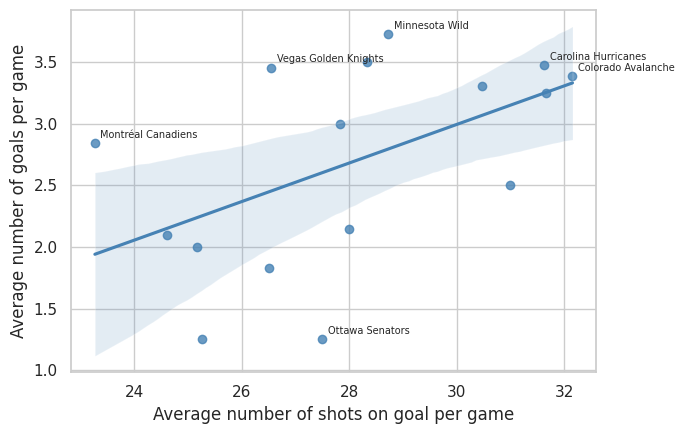

In [71]:
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.regplot(data=avgshots, x='Shot', y='Goal', ax=ax, color='steelblue')
for team in ['Carolina Hurricanes', 'Colorado Avalanche', 'Minnesota Wild',
             'Montréal Canadiens', 'Ottawa Senators', 'Vegas Golden Knights']:
    ax.annotate(team, (avgshots.loc[team, 'Shot'], avgshots.loc[team, 'Goal']),
                xytext=(4, 4), textcoords='offset points', fontsize=7)
ax.set_xlabel('Average number of shots on goal per game')
ax.set_ylabel('Average number of goals per game')
plt.tight_layout()
plt.show()

Связь видна - в среднем те команды, которые больше делают бросков - больше забивают

##№14

Учитываем все попытки: shot-on-goal, goal, missed-shot, blocked-shot. Каждая строка таблицы событий — одна попытка, idxmax() возвращает номер матча.

In [72]:
ATTEMPTS = ['shot-on-goal', 'goal', 'missed-shot', 'blocked-shot']
attempts = events[events['Play Type'].isin(ATTEMPTS)].copy()
attempts_per_game = attempts.groupby('Game ID').size()
idxmax = attempts_per_game.idxmax()
print(gameInfo(idxmax))


Carolina Hurricanes - Ottawa Senators (3 - 2, Final/2OT, 2026-04-20)


##№15

Чтобы удары хозяев всегда шли в правые ворота, а гостей — в левые, отражаем координаты (x, y) -> (-x, -y) в тех периодах, где команда атакует не те ворота. Вместо правила «нечётные периоды» используем поле Home Team's Defending Side: так преобразование корректно для любой игры, независимо от того, с какой стороны команды начинали матч.

Для заблокированных бросков в поле Team Making the Play указана бьющая команда (Player #1 — заблокировавший игрок, Player #2 — бросавший), поэтому они раскрашиваются по команде бросавшего.

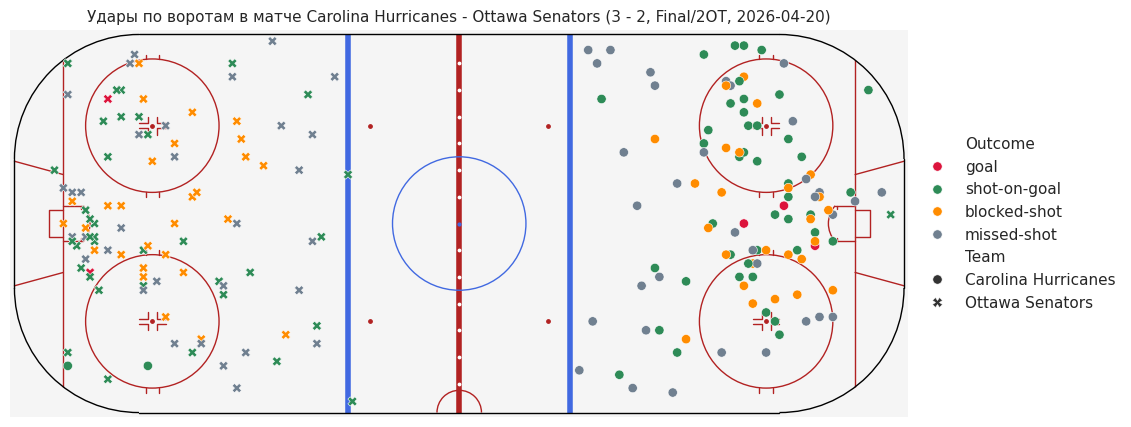

Хозяева (Каролина) — средний x ударов: 61.3
Гости (Оттава) — средний x ударов: -63.7


In [73]:
a = attempts[attempts['Game ID'] == idxmax].copy()
a_home = a['Team Making the Play'] == a['Home Team']
a_left = a["Home Team's Defending Side"] == 'left'

desired_X = np.where(a_home, 89, -89)
flip = np.where(a_home == a_left, 89, -89) != desired_X
sign = np.where(flip, -1, 1)
a['x'] = a['X Coordinate on the Ice Rink'] * sign
a['y'] = a['Y Coordinate on the Ice Rink'] * sign
a = a.rename(columns={'Play Type': 'Outcome', 'Team Making the Play': 'Team'})

plt.figure(figsize=(11, 4.6))
plot_rink()
sns.scatterplot(data=a, x='x', y='y', hue='Outcome', style='Team',
                hue_order=['goal', 'shot-on-goal', 'blocked-shot', 'missed-shot'],
                palette=['crimson', 'seagreen', 'darkorange', 'slategray'],
                s=45, edgecolor='white', linewidth=0.4)
plt.xlim(-101, 101); plt.ylim(-43.5, 43.5)
plt.gca().set_aspect('equal', adjustable='box')
plt.axis('off')
plt.legend(loc='center left', bbox_to_anchor=(1.0, 0.5), frameon=False)
plt.title(f'Удары по воротам в матче {gameInfo(idxmax)}', fontsize=11)
plt.tight_layout(pad=0.1)
plt.show()

print('Хозяева (Каролина) — средний x ударов:', a.loc[a_home.values, 'x'].mean().round(1))
print('Гости (Оттава) — средний x ударов:', a.loc[~a_home.values, 'x'].mean().round(1))

##№16

Посчитал количество голов каждого игрока и вывел топ 10

In [74]:
goals = events[events['Play Type'] == 'goal']
top_goals = goals['Player in the Event #1'].value_counts().rename('Goals')
top_goals.nlargest(10, keep='all')

,Goals
Player in the Event #1,
Brett Howden,14
Pavel Dorofeyev,12
Logan Stankoven,11
Mitch Marner,10
Jordan Staal,8
Nikolaj Ehlers,8
Nathan MacKinnon,7
Taylor Hall,7
Mark Stone,7


##№17

То же самое, что и в предыдущем пункте, только для голевых передач (по игроку 2 и 3 в событии)

In [75]:
assists = pd.concat([goals['Player in the Event #2'], goals['Player in the Event #3']]).dropna()
top_assists = assists.value_counts().rename('Assists')
top_assists.nlargest(10, keep='all')

,Assists
Jack Eichel,20
Mitch Marner,19
Jackson Blake,13
Lane Hutson,13
Taylor Hall,12
Martin Necas,12
Nick Suzuki,12
Shea Theodore,12
Quinn Hughes,11
Kirill Kaprizov,11


##№18

По резульатам предыдущих двух пунктов + внутри произведена сортировка по голам (чем больше, тем выше игрок в рейтинге)

In [76]:
points = pd.concat([top_goals, top_assists], axis=1).fillna(0).astype(int)
points['Points'] = points['Goals'] + points['Assists']
points.sort_values(['Points', 'Goals'], ascending=False).head(12)

,Goals,Assists,Points
Mitch Marner,10,19,29
Jack Eichel,2,20,22
Jackson Blake,7,13,20
Taylor Hall,7,12,19
Brett Howden,14,4,18
Nikolaj Ehlers,8,10,18
Shea Theodore,6,12,18
Pavel Dorofeyev,12,4,16
Logan Stankoven,11,5,16
Nick Suzuki,4,12,16


##№19

Число сыгранных игроком матчей определяем по таблице onice из №7 (игрок хотя бы раз был на льду). Бросками в створ снова считал shot-on-goal и goal, автор — Player in the Event #1.

In [77]:
games_played = onice.groupby('Player').size().rename('GP')

def per_game_leaders(event_types, name, min_gp=1):
    cnt = events[events['Play Type'].isin(event_types)]['Player in the Event #1'].value_counts().rename(name)
    t = pd.concat([games_played, cnt], axis=1).fillna(0)
    t[name] = t[name].astype(int); t['GP'] = t['GP'].astype(int)
    t[f'{name} per Game'] = t[name] / t['GP']
    t = t[t['GP'] >= min_gp]
    return t.nlargest(10, f'{name} per Game', keep='all')

per_game_leaders(['shot-on-goal', 'goal'], 'Shots')

,GP,Shots,Shots per Game
Jason Robertson,6,30,5.000
Dylan Guenther,6,27,4.500
Nikita Kucherov,7,31,4.429
Matt Boldy,11,48,4.364
Quinton Byfield,4,17,4.250
Darren Raddysh,7,28,4.000
Joel Eriksson Ek,6,24,4.000
Alex Laferriere,4,15,3.750
David Pastrnak,6,22,3.667
Nathan MacKinnon,13,47,3.615


##№20

Вывел лидеров по силовым приёмам

In [78]:
per_game_leaders(['hit'], 'Hits')

,GP,Hits,Hits per Game
Lawson Crouse,6,38,6.333
Alex Turcotte,1,6,6.000
Alexander Petrovic,1,6,6.000
Yakov Trenin,9,51,5.667
Dylan Cozens,4,22,5.500
Vasily Podkolzin,6,32,5.333
Carl Grundstrom,3,15,5.000
Ivan Barbashev,22,110,5.000
Marcus Foligno,11,55,5.000
Owen Tippett,6,29,4.833


##№21

Для каждого гола определяем вратаря защищающейся команды, находившегося на льду (Home/Away Team's Goalie). Затем для каждой пары «матч — вратарь, выходивший на лёд» считаем пропущенные голы и оставляем пары с нулём.

In [79]:
goalie_cols = ["Away Team's Goalie", "Home Team's Goalie"]
no_players = ((events["# of Away Team's Players on the Ice"] == 0) &
              (events["# of Home Team's Players on the Ice"] == 0))

gk = events[['Game ID', 'Play Type', 'Team Making the Play', 'Home Team'] + goalie_cols].copy()
gk.loc[no_players, goalie_cols] = events.groupby('Game ID')[goalie_cols].ffill().loc[no_players]

appear = pd.concat([gk[['Game ID', c]].set_axis(['Game ID', 'Goalie'], axis=1) for c in goalie_cols]
                   ).dropna().drop_duplicates()

gg = gk[gk['Play Type'] == 'goal']
conceded_by = np.where(gg['Team Making the Play'] == gg['Home Team'],
                       gg["Away Team's Goalie"], gg["Home Team's Goalie"])
ga = (pd.DataFrame({'Game ID': gg['Game ID'].values, 'Goalie': conceded_by})
        .dropna().groupby(['Game ID', 'Goalie']).size())
appear['GA'] = ga.reindex(pd.MultiIndex.from_frame(appear[['Game ID', 'Goalie']]), fill_value=0).values

clean = appear[appear['GA'] == 0].sort_values('Game ID')
clean['Game'] = clean['Game ID'].map(gameInfo)

clean['Goalie'].value_counts()

,count
Goalie,
Frederik Andersen,3
Dan Vladar,2
Andrei Vasilevskiy,1
Joonas Korpisalo,1
Scott Wedgewood,1
Brandon Bussi,1


In [80]:
likely_en = events.loc[gg.index, 'Shot Length'] > 89
ga2 = (pd.DataFrame({'Game ID': gg['Game ID'].values, 'Goalie': conceded_by})[~likely_en.values]
         .dropna().groupby(['Game ID', 'Goalie']).size())
appear['GA excl. EN'] = ga2.reindex(pd.MultiIndex.from_frame(appear[['Game ID', 'Goalie']]), fill_value=0).values
extra = appear[(appear['GA excl. EN'] == 0) & (appear['GA'] > 0)].copy()
extra['Game'] = extra['Game ID'].map(gameInfo)
extra[['Goalie', 'Game', 'GA', 'GA excl. EN']]

,Goalie,Game,GA,GA excl. EN


##№22

В рамках данного вопроса я хочу рассмотреть рейтинг игроков по набранным очкам для fantasy league ESPN (брал в расчёт только голы, голевые передачи, удары в створ и заблокированные удары), не включая вратарей. Систему оценивания я брал отсюда: https://outliershockey.com/how-are-points-scored-on-espn-fantasy-hockey.html.

In [81]:
SCORING = {'Goals': 3, 'Assists': 2, 'Shots on Goal': 0.5, 'Blocked Shots': 0.5}

goals = events[events['Play Type'] == 'goal']
shots_on_goal = events[events['Play Type'].isin(['shot-on-goal', 'goal'])]
blocks = events[events['Play Type'] == 'blocked-shot']

fantasy = pd.DataFrame({
    'Goals': goals['Player in the Event #1'].value_counts(),
    'Assists': pd.concat([goals['Player in the Event #2'],
                          goals['Player in the Event #3']]).value_counts(),
    'Shots on Goal': shots_on_goal['Player in the Event #1'].value_counts(),
    'Blocked Shots': blocks['Player in the Event #1'].value_counts(),
}).fillna(0).astype(int)

fantasy['Fantasy Points'] = sum(fantasy[stat] * pts for stat, pts in SCORING.items())

fantasy.nlargest(5, 'Fantasy Points')

,Goals,Assists,Shots on Goal,Blocked Shots,Fantasy Points
Mitch Marner,10,19,57,13,103.0
Shea Theodore,6,12,42,58,92.0
Jack Eichel,2,20,52,30,87.0
Taylor Hall,7,12,55,14,79.5
Pavel Dorofeyev,12,4,58,8,77.0
